In [17]:
from google.colab import userdata
import sys, os, subprocess

TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw3"

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap
import importlib
importlib.reload(colab_bootstrap)
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw3:=== Session started for hw3 ===


Working directory: /content/data266-5937/hw3
[main e82db79] hw3: session start
 1 file changed, 12 insertions(+)
 


In [3]:
SID4 = 5937
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

INFO:/content/data266-5937/hw3:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


In [4]:
!pip uninstall -y openai langchain-openai langchain-core langchain
!pip install --no-cache-dir langchain langchain-openai langchain-core openai


Found existing installation: openai 3.13.0
Uninstalling openai-3.13.0:
  Successfully uninstalled openai-3.13.0
Found existing installation: langchain-openai 1.6.2
Uninstalling langchain-openai-1.6.2:
  Successfully uninstalled langchain-openai-1.6.2
Found existing installation: langchain-core 1.6.3
Uninstalling langchain-core-1.6.3:
  Successfully uninstalled langchain-core-1.6.3
Found existing installation: langchain 1.4.0
Uninstalling langchain-1.4.0:
  Successfully uninstalled langchain-1.4.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.7/41.7 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.5/161.5 kB 20.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 kB 359.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.8/571.8 kB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 189.1 MB/s eta 0:00:00


In [3]:
from google.colab import userdata
from langchain_core.prompts import PromptTemplate, ChatPromptTemplate
from langchain_openai import ChatOpenAI

import os

if 'logger' not in globals():
    import sys
    import importlib


    TOKEN = userdata.get('GITHUB_TOKEN')
    USERNAME = "vedika0806"
    REPO = "data266-5937"
    HW = "hw3"

    # Ensure sys.path includes the common directory where colab_bootstrap resides
    repo_path_common = f"/content/{REPO}/common"
    if repo_path_common not in sys.path:
        sys.path.append(repo_path_common)

    # Re-import and reload colab_bootstrap to ensure functions are available
    import colab_bootstrap
    importlib.reload(colab_bootstrap)
    from colab_bootstrap import setup_repo, get_logger

    # Re-initialize HW_PATH and logger
    HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
    logger = get_logger(HW_PATH)
    logger.info(f"=== Logger re-initialized in G3-G3kcHv8UL after kernel likely restarted ===")


os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_API_KEY')
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

logger.info("Initialized LangChain LLM client for prompt engineering experiments")

INFO:/content/data266-5937/hw3:=== Logger re-initialized in G3-G3kcHv8UL after kernel likely restarted ===


Working directory: /content/data266-5937/hw3


INFO:/content/data266-5937/hw3:Initialized LangChain LLM client for prompt engineering experiments


In [6]:
!pip -q install langchain langchain-groq
from langchain_core.prompts import PromptTemplate, FewShotPromptTemplate
import os
from langchain_groq import ChatGroq

os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')  # add this in Colab Secrets

llm = ChatGroq(model="llama-3.1-8b-instant", temperature=0)

logger.info("Initialized LangChain LLM client (Groq) for prompt engineering experiments")

INFO:/content/data266-5937/hw3:Initialized LangChain LLM client (Groq) for prompt engineering experiments


In [8]:
import requests

resp = requests.get(
    "https://api.groq.com/openai/v1/models",
    headers={"Authorization": f"Bearer {userdata.get('GROQ_API_KEY')}"}
)
models = resp.json()
for m in models.get("data", []):
    print(m["id"])

whisper-large-v3-turbo
openai/gpt-oss-safeguard-20b
groq/compound-mini
whisper-large-v3
allam-2-7b
qwen/qwen3.6-27b
qwen/qwen3.8-27b
meta-llama/llama-prompt-guard-2-86m
groq/compound
openai/gpt-oss-120b
canopylabs/orpheus-arabic-saudi
meta-llama/llama-prompt-guard-2-22m
openai/gpt-oss-20b
canopylabs/orpheus-v1-english


In [10]:
!pip -q install langchain langchain-groq

import os
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate, FewShotPromptTemplate

os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')

llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0)

logger.info("Initialized LangChain LLM client (Groq, model=openai/gpt-oss-120b) for prompt engineering experiments")

INFO:/content/data266-5937/hw3:Initialized LangChain LLM client (Groq, model=openai/gpt-oss-120b) for prompt engineering experiments


In [11]:
zs_prompt_1 = PromptTemplate.from_template(
    "Solve this math problem and give only the final number.\n\nProblem: {problem}\nAnswer:"
)
zs_prompt_2 = PromptTemplate.from_template(
    "Answer the following logical reasoning question.\n\nQuestion: {question}\nAnswer:"
)

zs_1 = llm.invoke(zs_prompt_1.format(problem="A train travels 60 miles in 1.5 hours. What is its speed in mph?"))
zs_2 = llm.invoke(zs_prompt_2.format(question="All cats are mammals. Some mammals are black. Can we conclude some cats are black?"))

print("Zero-Shot Example 1:\n", zs_1.content)
print("\nZero-Shot Example 2:\n", zs_2.content)

logger.info("Ran Zero-Shot prompting examples (math + logical reasoning)")

INFO:/content/data266-5937/hw3:Ran Zero-Shot prompting examples (math + logical reasoning)


Zero-Shot Example 1:
 40

Zero-Shot Example 2:
 **Answer:** No, we cannot conclude that some cats are black.

**Explanation**

The two premises are:

1. **All cats are mammals.**  
   (Every member of the set *Cats* is also a member of the set *Mammals*.)

2. **Some mammals are black.**  
   (There exists at least one member of the set *Mammals* that is also a member of the set *Black*.)

From these we know that the set of cats is a subset of mammals, and that the set of black mammals is non‑empty. However, the black mammals could be entirely outside the cat subset (e.g., black dogs, black bears, etc.). The information given does not guarantee any overlap between the *Cats* set and the *Black* set.

In formal terms, the syllogism is invalid:

- Premise: ∀x (Cat(x) → Mammal(x))
- Premise: ∃x (Mammal(x) ∧ Black(x))
- Desired conclusion: ∃x (Cat(x) ∧ Black(x))

The conclusion does not follow logically from the premises; a counterexample (all black mammals are non‑cats) shows the inference

In [12]:
examples_math = [
    {"problem": "2 + 3 * 4", "answer": "14"},
    {"problem": "10 - 2 * 3", "answer": "4"},
]
fs_template_math = PromptTemplate.from_template("Problem: {problem}\nAnswer: {answer}")
fs_prompt_math = FewShotPromptTemplate(
    examples=examples_math,
    example_prompt=fs_template_math,
    suffix="Problem: {problem}\nAnswer:",
    input_variables=["problem"],
)

examples_logic = [
    {"question": "All birds can fly. Penguins are birds. Can penguins fly?", "answer": "No, because the premise is false in reality; logically yes, but factually no."},
    {"question": "If it rains, the ground gets wet. The ground is wet. Did it rain?", "answer": "Not necessarily — wet ground doesn't guarantee rain (could be another cause)."},
]
fs_template_logic = PromptTemplate.from_template("Question: {question}\nAnswer: {answer}")
fs_prompt_logic = FewShotPromptTemplate(
    examples=examples_logic,
    example_prompt=fs_template_logic,
    suffix="Question: {question}\nAnswer:",
    input_variables=["question"],
)

fs_1 = llm.invoke(fs_prompt_math.format(problem="7 + 5 * 2"))
fs_2 = llm.invoke(fs_prompt_logic.format(question="If the alarm rings, the building is on fire. The building is on fire. Did the alarm ring?"))

print("Few-Shot Example 1:\n", fs_1.content)
print("\nFew-Shot Example 2:\n", fs_2.content)

logger.info("Ran Few-Shot prompting examples (math + logical reasoning)")

INFO:/content/data266-5937/hw3:Ran Few-Shot prompting examples (math + logical reasoning)


Few-Shot Example 1:
 **Answer:** 17

Few-Shot Example 2:
 **Answer:** Not necessarily — the building being on fire does not guarantee that the alarm rang.  

The statement “If the alarm rings, the building is on fire” (alarm → fire) tells us that an alarm is a sufficient condition for a fire, but it is not a necessary condition. The fire could have started for other reasons (e.g., a short circuit, arson, etc.), so we cannot infer that the alarm definitely rang.


In [13]:
cot_prompt_1 = PromptTemplate.from_template(
    "Solve step by step, showing your reasoning, then give the final answer.\n\n"
    "Problem: {problem}\nLet's think step by step."
)
cot_prompt_2 = PromptTemplate.from_template(
    "Solve step by step, showing your reasoning, then give the final answer.\n\n"
    "Question: {question}\nLet's think step by step."
)

cot_1 = llm.invoke(cot_prompt_1.format(problem="A store sells apples for $2 each. If you buy 3 apples and get a 10% discount, how much do you pay?"))
cot_2 = llm.invoke(cot_prompt_2.format(question="John is taller than Mary. Mary is taller than Sue. Is John taller than Sue?"))

print("CoT Example 1:\n", cot_1.content)
print("\nCoT Example 2:\n", cot_2.content)

logger.info("Ran explicit Chain-of-Thought prompting examples")

INFO:/content/data266-5937/hw3:Ran explicit Chain-of-Thought prompting examples


CoT Example 1:
 **Step‑by‑step solution**

1. **Find the regular cost of the apples**  
   - Price per apple = \$2  
   - Number of apples bought = 3  
   - Regular total cost = \(3 \times \$2 = \$6\).

2. **Calculate the amount of the discount**  
   - Discount rate = 10 %  
   - Discount amount = 10 % of the regular total cost  
   \[
   \text{Discount} = 0.10 \times \$6 = \$0.60.
   \]

3. **Subtract the discount from the regular total**  
   \[
   \text{Amount to pay} = \$6 - \$0.60 = \$5.40.
   \]

---

**Final answer:** You pay **\$5.40**.

CoT Example 2:
 **Step‑by‑step reasoning**

1. **Given statements**  
   - *John is taller than Mary.*  
   - *Mary is taller than Sue.*

2. **Interpret the relationships**  
   - “A is taller than B” means the height of A > height of B.

3. **Chain the inequalities**  
   - From the first statement: height(John) > height(Mary)  
   - From the second statement: height(Mary) > height(Sue)

4. **Combine the two inequalities**  
   - If height(Jo

In [14]:
zscot_prompt_1 = PromptTemplate.from_template("{problem}\nLet's think step by step.")
zscot_prompt_2 = PromptTemplate.from_template("{question}\nLet's think step by step.")

zscot_1 = llm.invoke(zscot_prompt_1.format(problem="If a car travels at 45 mph for 2 hours and then 60 mph for 1 hour, what is the total distance traveled?"))
zscot_2 = llm.invoke(zscot_prompt_2.format(question="A is B's father. B is C's mother. What is A to C?"))

print("Zero-Shot CoT Example 1:\n", zscot_1.content)
print("\nZero-Shot CoT Example 2:\n", zscot_2.content)

logger.info("Ran Zero-Shot CoT prompting examples")

INFO:/content/data266-5937/hw3:Ran Zero-Shot CoT prompting examples


Zero-Shot CoT Example 1:
 To find the total distance, calculate the distance covered in each segment and then add them together.

1. **First segment:**  
   - Speed = 45 mph  
   - Time = 2 hours  
   - Distance = speed × time = 45 mph × 2 h = **90 miles**

2. **Second segment:**  
   - Speed = 60 mph  
   - Time = 1 hour  
   - Distance = speed × time = 60 mph × 1 h = **60 miles**

3. **Total distance:**  
   - 90 miles + 60 miles = **150 miles**

**Answer:** The car travels a total of **150 miles**.

Zero-Shot CoT Example 2:
 A is C’s grandfather.  (A is the father of B, who is C’s mother, so A is C’s paternal grandfather.)


In [15]:
meta_prompt_1 = PromptTemplate.from_template(
    "You are a prompt engineer. First, design the best possible prompt to solve the "
    "following task, then use that prompt yourself to produce the final answer.\n\n"
    "Task: {task}"
)
meta_prompt_2 = PromptTemplate.from_template(
    "Before answering, briefly state what strategy (e.g., decomposition, analogy, "
    "step-by-step) is most appropriate for this task, then apply it.\n\n"
    "Task: {task}"
)

meta_1 = llm.invoke(meta_prompt_1.format(task="Determine whether 91 is a prime number."))
meta_2 = llm.invoke(meta_prompt_2.format(task="Three friends split a $90 bill unequally: Alice pays twice what Bob pays, and Carol pays $10 more than Bob. How much does each pay?"))

print("Meta-Prompting Example 1:\n", meta_1.content)
print("\nMeta-Prompting Example 2:\n", meta_2.content)

logger.info("Ran Meta-Prompting examples")

INFO:/content/data266-5937/hw3:Ran Meta-Prompting examples


Meta-Prompting Example 1:
 **Designed Prompt**

> *You are a mathematics expert. Determine whether the integer 91 is a prime number. Explain your reasoning step‑by‑step, including any factor checks you perform, and give a clear final conclusion (prime or not prime).*

---

**Result Using the Prompt**

91 is **not** a prime number.

**Reasoning**

1. A prime number has exactly two distinct positive divisors: 1 and itself.
2. To test 91, check for divisors up to √91 ≈ 9.5.
3. Test small primes:
   - 2 → 91 is odd, not divisible.
   - 3 → 9 + 1 = 10, not a multiple of 3.
   - 5 → does not end in 0 or 5.
   - 7 → 91 ÷ 7 = 13, an integer.
4. Since 7 divides 91, we have the factorization 91 = 7 × 13.
5. Both 7 and 13 are greater than 1 and less than 91, so 91 has more than two divisors.

**Conclusion:** 91 is a composite number (not prime).

Meta-Prompting Example 2:
 **Strategy:** Set up and solve a simple system of linear equations (decomposition of the total amount into each person’s shar

In [16]:
def tree_of_thoughts(task, n_branches=3):
    branch_prompt = PromptTemplate.from_template(
        "Task: {task}\nPropose one possible reasoning path (just this one path) toward the solution."
    )
    branches = [llm.invoke(branch_prompt.format(task=task)).content for _ in range(n_branches)]

    eval_prompt = PromptTemplate.from_template(
        "Task: {task}\n\nHere are {n} candidate reasoning paths:\n{paths}\n\n"
        "Evaluate each briefly, pick the best one, and give the final answer."
    )
    joined = "\n---\n".join(f"Path {i+1}: {b}" for i, b in enumerate(branches))
    final = llm.invoke(eval_prompt.format(task=task, n=n_branches, paths=joined))
    return branches, final.content

tot_branches_1, tot_final_1 = tree_of_thoughts(
    "A farmer has chickens and cows totaling 20 heads and 56 legs. How many of each animal?"
)
tot_branches_2, tot_final_2 = tree_of_thoughts(
    "Plan the most efficient order to visit 4 errands (bank, pharmacy, grocery, post office) given the bank closes soonest."
)

print("ToT Example 1 final answer:\n", tot_final_1)
print("\nToT Example 2 final answer:\n", tot_final_2)

logger.info("Ran Tree-of-Thoughts examples")


INFO:/content/data266-5937/hw3:Ran Tree-of-Thoughts examples


ToT Example 1 final answer:
 **Evaluation of the three reasoning paths**

| Path | Strengths | Weaknesses |
|------|-----------|------------|
| **1** | • Clearly introduces variables.<br>• Shows the translation to equations and a simplification step.<br>• Uses elimination cleanly and includes a verification of both heads and legs.<br>• Ends with a concise conclusion. | • None significant – the presentation is complete and easy to follow. |
| **2** | • Same correct algebra as Path 1.<br>• Adds an extra “Conclusion” heading. | • Repeats the same steps without any improvement; the extra heading is unnecessary. |
| **3** | • Identical to Path 2 (and thus to Path 1) in content. | • No added clarity or brevity over Path 1. |

**Best choice:** **Path 1** – it presents the solution in a logical, step‑by‑step manner, includes a verification, and is succinct.

---

### Final Answer
Let \(c\) be the number of chickens and \(k\) the number of cows.

\[
\begin{cases}
c + k = 20 &\text{(heads)}\\[4p

NameError: name 'git_commit_push' is not defined

In [18]:
git_commit_push(REPO_PATH, f"{HW}: completed Part 1 prompt engineering techniques")

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
 


In [24]:
SEED = 5937
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(SEED)

text = ("Neural networks are powerful models for learning representations from data. "
        "They consist of layers of interconnected neurons. "
        "Attention mechanisms allow models to focus on relevant parts of the input. "
        "Transformers rely entirely on attention instead of recurrence. "
        "Autoregressive models generate text one token at a time.")

# word-level tokenization (strip punctuation, lowercase)
import re
raw_tokens = re.findall(r"[A-Za-z']+|[.,]", text)
tokens = [t.lower() for t in raw_tokens]

vocab = sorted(set(tokens))
stoi = {w: i for i, w in enumerate(vocab)}
itos = {i: w for w, i in stoi.items()}
vocab_size = len(vocab)

token_ids = torch.tensor([stoi[t] for t in tokens], dtype=torch.long)

print(f"Num tokens: {len(tokens)}, Vocab size: {vocab_size}")
print(tokens)

logger.info(f"Tokenized dataset: {len(tokens)} tokens, vocab size {vocab_size}")

INFO:/content/data266-5937/hw3:Tokenized dataset: 51 tokens, vocab size 40


Num tokens: 51, Vocab size: 40
['neural', 'networks', 'are', 'powerful', 'models', 'for', 'learning', 'representations', 'from', 'data', '.', 'they', 'consist', 'of', 'layers', 'of', 'interconnected', 'neurons', '.', 'attention', 'mechanisms', 'allow', 'models', 'to', 'focus', 'on', 'relevant', 'parts', 'of', 'the', 'input', '.', 'transformers', 'rely', 'entirely', 'on', 'attention', 'instead', 'of', 'recurrence', '.', 'autoregressive', 'models', 'generate', 'text', 'one', 'token', 'at', 'a', 'time', '.']


In [25]:
class SelfAttentionLM(nn.Module):
    def __init__(self, vocab_size, d_model=32, seq_len=None):
        super().__init__()
        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_embedding = nn.Embedding(seq_len, d_model)

        # Q, K, V projections (Section 3.2, Attention Is All You Need)
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)

        self.out_proj = nn.Linear(d_model, d_model)
        self.lm_head = nn.Linear(d_model, vocab_size)

    def attention(self, x, causal_mask=False):
        B_or_T, d = x.shape  # x: (seq_len, d_model), no batch dim for simplicity
        Q = self.W_q(x)
        K = self.W_k(x)
        V = self.W_v(x)

        scores = Q @ K.T / np.sqrt(self.d_model)  # (T, T)

        if causal_mask:
            T = scores.size(0)
            mask = torch.triu(torch.ones(T, T), diagonal=1).bool()
            scores = scores.masked_fill(mask, float("-inf"))

        weights = F.softmax(scores, dim=-1)  # (T, T)
        out = weights @ V                    # (T, d_model)
        return out, weights

    def forward(self, token_ids, causal_mask=False):
        T = token_ids.size(0)
        positions = torch.arange(T)
        x = self.embedding(token_ids) + self.pos_embedding(positions)

        attn_out, attn_weights = self.attention(x, causal_mask=causal_mask)
        h = self.out_proj(attn_out)
        logits = self.lm_head(h)  # (T, vocab_size)
        return logits, attn_weights

seq_len = len(token_ids)
model_unmasked = SelfAttentionLM(vocab_size, d_model=32, seq_len=seq_len)

logger.info("Defined SelfAttentionLM with scaled dot-product self-attention from scratch")

INFO:/content/data266-5937/hw3:Defined SelfAttentionLM with scaled dot-product self-attention from scratch


Epoch 0: loss = 3.6988
Epoch 50: loss = 0.3199
Epoch 100: loss = 0.0939
Epoch 150: loss = 0.1445
Epoch 200: loss = 0.0837
Epoch 250: loss = 0.0834


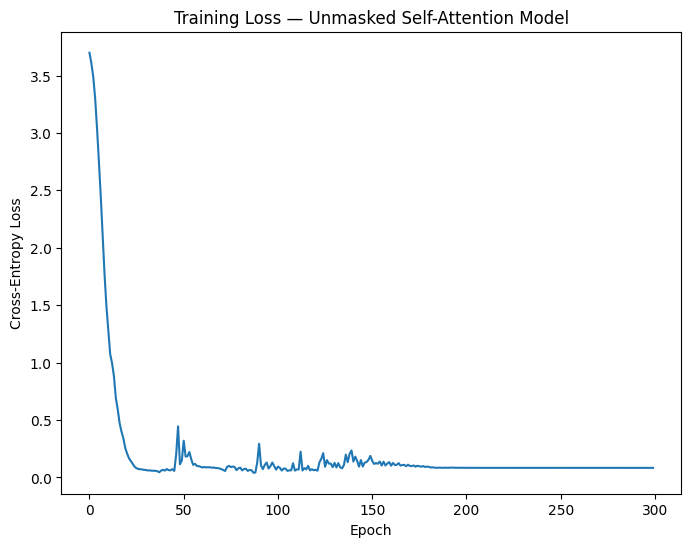

INFO:/content/data266-5937/hw3:Trained unmasked self-attention model, final loss=0.0833


[main 086fcb6] hw3: train unmasked self-attention model
 2 files changed, 3 insertions(+)
 create mode 100644 hw3/loss_unmasked.png
 


In [26]:
def train_model(model, token_ids, causal_mask, epochs=300, lr=0.01):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    inputs = token_ids[:-1]
    targets = token_ids[1:]

    losses = []
    for epoch in range(epochs):
        optimizer.zero_grad()
        logits, attn_weights = model(inputs, causal_mask=causal_mask)
        loss = F.cross_entropy(logits, targets)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if epoch % 50 == 0:
            print(f"Epoch {epoch}: loss = {loss.item():.4f}")

    return losses

torch.manual_seed(SEED)
losses_unmasked = train_model(model_unmasked, token_ids, causal_mask=False, epochs=300)

plt.figure(figsize=(8,6))
plt.plot(losses_unmasked)
plt.title("Training Loss — Unmasked Self-Attention Model")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.savefig(f"{HW_PATH}/loss_unmasked.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

logger.info(f"Trained unmasked self-attention model, final loss={losses_unmasked[-1]:.4f}")
git_commit_push(REPO_PATH, f"{HW}: train unmasked self-attention model")

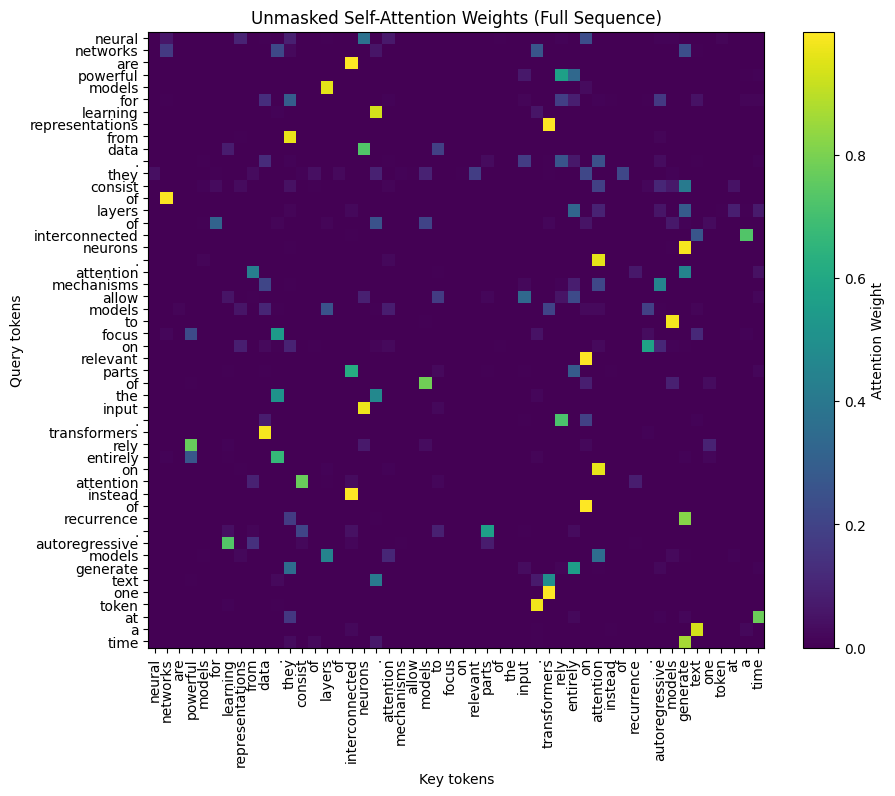

INFO:/content/data266-5937/hw3:Computed and visualized unmasked self-attention heatmap


160611 bytes
[main abf75ff] hw3: add unmasked attention heatmap
 2 files changed, 1 insertion(+)
 create mode 100644 hw3/attention_unmasked_heatmap.png
 


In [27]:
model_unmasked.eval()
with torch.no_grad():
    _, attn_weights_unmasked = model_unmasked(token_ids[:-1], causal_mask=False)

attn_matrix = attn_weights_unmasked.numpy()
labels = [itos[i.item()] for i in token_ids[:-1]]

plt.figure(figsize=(10,8))
plt.imshow(attn_matrix, cmap="viridis")
plt.colorbar(label="Attention Weight")
plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)
plt.title("Unmasked Self-Attention Weights (Full Sequence)")
plt.xlabel("Key tokens")
plt.ylabel("Query tokens")
plt.savefig(f"{HW_PATH}/attention_unmasked_heatmap.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

print(os.path.getsize(f"{HW_PATH}/attention_unmasked_heatmap.png"), "bytes")

logger.info("Computed and visualized unmasked self-attention heatmap")
git_commit_push(REPO_PATH, f"{HW}: add unmasked attention heatmap")

Epoch 0: loss = 3.7050
Epoch 50: loss = 0.1027
Epoch 100: loss = 0.1629
Epoch 150: loss = 0.1604
Epoch 200: loss = 0.1599
Epoch 250: loss = 0.1598


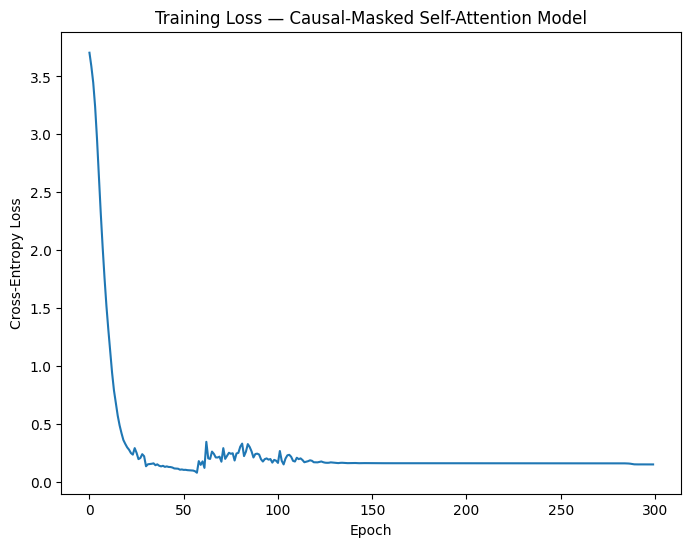

INFO:/content/data266-5937/hw3:Trained causal-masked self-attention model, final loss=0.1497


[main f6a09e6] hw3: train causal-masked self-attention model
 2 files changed, 1 insertion(+)
 create mode 100644 hw3/loss_masked.png
 


In [28]:
torch.manual_seed(SEED)
model_masked = SelfAttentionLM(vocab_size, d_model=32, seq_len=seq_len)

losses_masked = train_model(model_masked, token_ids, causal_mask=True, epochs=300)

plt.figure(figsize=(8,6))
plt.plot(losses_masked)
plt.title("Training Loss — Causal-Masked Self-Attention Model")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.savefig(f"{HW_PATH}/loss_masked.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

logger.info(f"Trained causal-masked self-attention model, final loss={losses_masked[-1]:.4f}")
git_commit_push(REPO_PATH, f"{HW}: train causal-masked self-attention model")

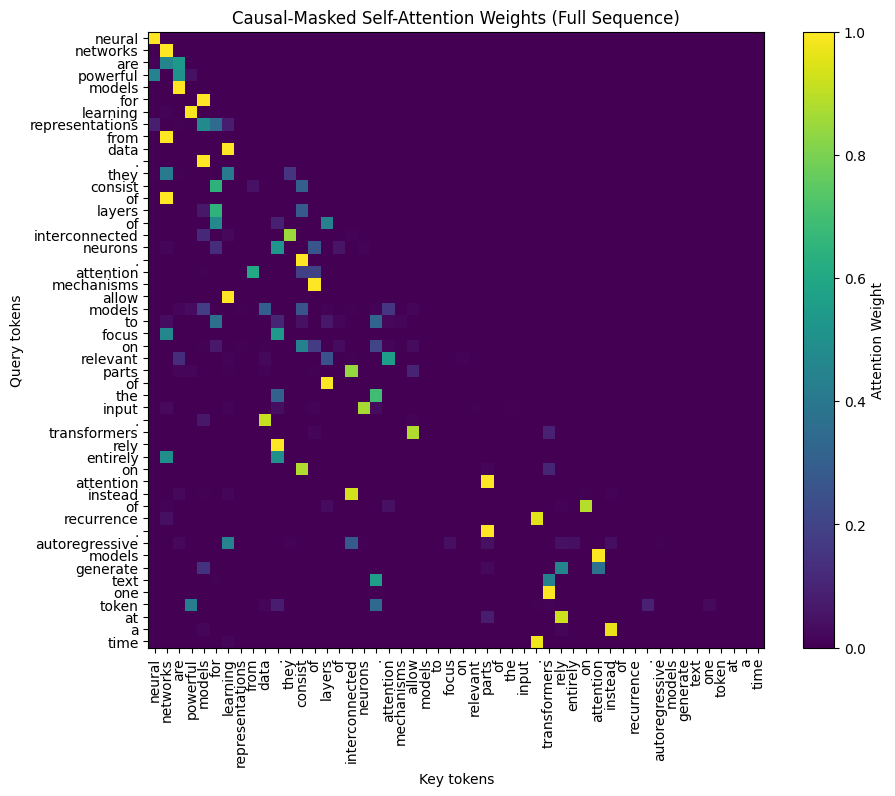

INFO:/content/data266-5937/hw3:Computed and visualized causal-masked self-attention heatmap


160355 bytes
[main 4270e37] hw3: add masked attention heatmap
 2 files changed, 1 insertion(+)
 create mode 100644 hw3/attention_masked_heatmap.png
 


In [29]:
model_masked.eval()
with torch.no_grad():
    _, attn_weights_masked = model_masked(token_ids[:-1], causal_mask=True)

attn_matrix_masked = attn_weights_masked.numpy()
labels = [itos[i.item()] for i in token_ids[:-1]]

plt.figure(figsize=(10,8))
plt.imshow(attn_matrix_masked, cmap="viridis")
plt.colorbar(label="Attention Weight")
plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)
plt.title("Causal-Masked Self-Attention Weights (Full Sequence)")
plt.xlabel("Key tokens")
plt.ylabel("Query tokens")
plt.savefig(f"{HW_PATH}/attention_masked_heatmap.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

print(os.path.getsize(f"{HW_PATH}/attention_masked_heatmap.png"), "bytes")

logger.info("Computed and visualized causal-masked self-attention heatmap")
git_commit_push(REPO_PATH, f"{HW}: add masked attention heatmap")

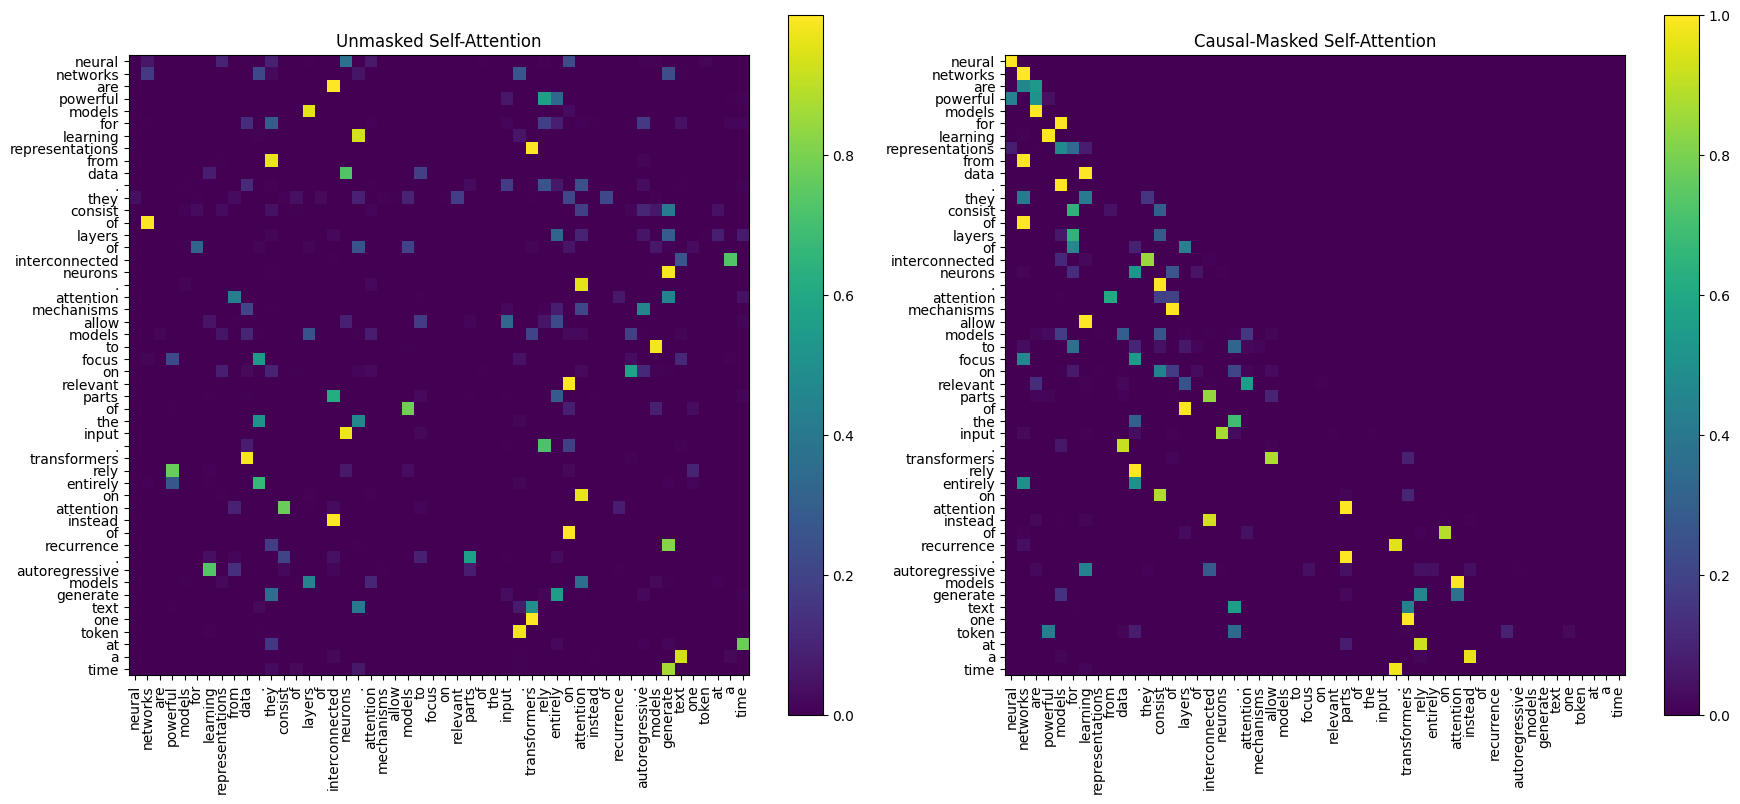

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

im0 = axes[0].imshow(attn_matrix, cmap="viridis")
axes[0].set_xticks(range(len(labels))); axes[0].set_xticklabels(labels, rotation=90)
axes[0].set_yticks(range(len(labels))); axes[0].set_yticklabels(labels)
axes[0].set_title("Unmasked Self-Attention")
fig.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(attn_matrix_masked, cmap="viridis")
axes[1].set_xticks(range(len(labels))); axes[1].set_xticklabels(labels, rotation=90)
axes[1].set_yticks(range(len(labels))); axes[1].set_yticklabels(labels)
axes[1].set_title("Causal-Masked Self-Attention")
fig.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.savefig(f"{HW_PATH}/attention_comparison.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()


In [31]:
part2_notes = f"""
## Part 2 — Causal Masking Comparison

- **Unmasked model** final training loss: {losses_unmasked[-1]:.4f}
- **Masked model** final training loss: {losses_masked[-1]:.4f}
In unmasked self-attention, tokens attend to both past and future positions. Early tokens like "neural" attend to later tokens like "layers" or "entirely". That is the heatmap shows correlation coefficient spread all over the grid.
In causal masked self attention (like that in autoregressive models), the upper triangle is exactly zero, because each token attends to itself and the prior tokens. This matches the decoder self-attention behavior described in
Section 3.2.3 of *Attention Is All You Need*, which prevents positions from attending to subsequent positions to preserve the autoregressive property.
The loss trajectory of the causal masked self attention has fluctuations until 100 epochs after which it settles. The same is not the case with the unmasked self attention model because it trains on fixed, predictable text targets, allowing the model to quickly memorize patterns and settle early.Unmasked attention relies on random, dynamic masking that changes every epoch, presenting a moving target that forces longer training fluctuations.
"""
with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(part2_notes)

print(part2_notes)
logger.info("Added Part 2 causal masking comparison to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add Part 2 causal masking writeup")

INFO:/content/data266-5937/hw3:Added Part 2 causal masking comparison to METRICS.md



## Part 2 — Causal Masking Comparison

- **Unmasked model** final training loss: 0.0833
- **Masked model** final training loss: 0.1497
In unmasked self-attention, tokens attend to both past and future positions. Early tokens like "neural" attend to later tokens like "layers" or "entirely". That is the heatmap shows correlation coefficient spread all over the grid.
In causal masked self attention (like that in autoregressive models), the upper triangle is exactly zero, because each token attends to itself and the prior tokens. This matches the decoder self-attention behavior described in
Section 3.2.3 of *Attention Is All You Need*, which prevents positions from attending to subsequent positions to preserve the autoregressive property.
The loss trajectory of the causal masked self attention has fluctuations until 100 epochs after which it settles. The same is not the case with the unmasked self attention model because it trains on fixed, predictable text targets, allowing the model to 

In [32]:
comparison_notes = """
## Part 1 — Prompt Engineering Technique Comparison

- **Zero-Shot**: Fast, no examples needed, but occasionally skips reasoning steps and
  can misfire on tasks requiring multi-step logic.
- **Few-Shot**: Anchors output format/style via examples; improved consistency on the
  logic questions vs zero-shot, but quality depends heavily on example choice.
- **Chain-of-Thought (explicit)**: Produces visible intermediate steps, catches
  arithmetic/logic errors that zero-shot missed, at the cost of longer output.
- **Zero-Shot CoT**: Nearly matched explicit CoT quality just by appending
  "Let's think step by step," with less prompt-engineering effort.
- **Meta-Prompting**: Model articulates a strategy before solving; useful for
  ambiguous/multi-part tasks, but adds overhead for simple problems.
- **Tree of Thoughts**: Generated multiple candidate reasoning paths and picked the
  best; most robust on the constraint-satisfaction (chickens/cows) problem, but
  most expensive (multiple LLM calls).

**Overall finding**: reasoning-heavy tasks (arithmetic word problems, multi-step
logic) benefited most from CoT/ToT; simple factual asks did fine with Zero-Shot.
"""

with open(f"{HW_PATH}/METRICS.md", "a") as f:
    f.write(comparison_notes)

print(comparison_notes)
logger.info("Added Part 1 comparison notes to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add Part 1 comparison notes to METRICS.md")

INFO:/content/data266-5937/hw3:Added Part 1 comparison notes to METRICS.md



## Part 1 — Prompt Engineering Technique Comparison

- **Zero-Shot**: Fast, no examples needed, but occasionally skips reasoning steps and
  can misfire on tasks requiring multi-step logic.
- **Few-Shot**: Anchors output format/style via examples; improved consistency on the
  logic questions vs zero-shot, but quality depends heavily on example choice.
- **Chain-of-Thought (explicit)**: Produces visible intermediate steps, catches
  arithmetic/logic errors that zero-shot missed, at the cost of longer output.
- **Zero-Shot CoT**: Nearly matched explicit CoT quality just by appending
  "Let's think step by step," with less prompt-engineering effort.
- **Meta-Prompting**: Model articulates a strategy before solving; useful for
  ambiguous/multi-part tasks, but adds overhead for simple problems.
- **Tree of Thoughts**: Generated multiple candidate reasoning paths and picked the
  best; most robust on the constraint-satisfaction (chickens/cows) problem, but
  most expensive (multiple LLM c

In [33]:
!ls -la {HW_PATH}
!cat {HW_PATH}/METRICS.md
!cd {REPO_PATH} && git log --oneline -10
!cd {REPO_PATH} && git status

total 612
drwxr-xr-x 2 root root   4096 Sep 14 04:37 .
drwxr-xr-x 8 root root   4096 Sep 14 02:29 ..
-rw-r--r-- 1 root root 182641 Sep 14 03:24 attention_comparison.png
-rw-r--r-- 1 root root 160355 Sep 14 03:24 attention_masked_heatmap.png
-rw-r--r-- 1 root root 160611 Sep 14 03:23 attention_unmasked_heatmap.png
-rw-r--r-- 1 root root  46510 Sep 14 03:23 loss_masked.png
-rw-r--r-- 1 root root  48220 Sep 14 03:23 loss_unmasked.png
-rw-r--r-- 1 root root   2365 Sep 14 04:41 METRICS.md
-rw-r--r-- 1 root root   1865 Sep 14 04:41 RUN_LOG.txt

## Part 2 — Causal Masking Comparison

- **Unmasked model** final training loss: 0.0833
- **Masked model** final training loss: 0.1497
In unmasked self-attention, tokens attend to both past and future positions. Early tokens like "neural" attend to later tokens like "layers" or "entirely". That is the heatmap shows correlation coefficient spread all over the grid.
In causal masked self attention (like that in autoregressive models), the upper triangle